# Example neurons and the relationality metric → `figure_example_neurons.pdf`, `figure_example_neurons_metric.pdf`

**First figure: real neurons.** One column per neuron selected in `UNITS` (comment lines in or
out; columns appear in list order). Each ring shows the stimuli that drive the neuron most, found
from its **measured** responses:

1. **Empirical tuning curve.** For each inter-object angle in `SEPARATIONS` and chord midpoints
   every `360 / N_DENSE` degrees, average the firing rate (0–2 s, stimulus + delay) over the
   2-object trials whose two objects are both within `WINDOW_DEG` of that chord's ends. This is
   `tuning_plots.ipynb`'s binning (`example_neurons_lib.curve`, checked against
   `tuning_lib.unit_curves`).
2. **Smooth** the curve with a circular Gaussian of `SMOOTH_DEG`, `tuning_plots`' line-row
   smoothing.
3. **Local maxima.** Keep the highest `SEPARATIONS[sep]` peaks that stand at least
   `MIN_PROMINENCE_FRAC` of the neuron's response range above their surroundings. The 180°-apart
   curve repeats every half turn, so it is searched over half the circle.

Each ring is turned by its unit's `rotation_deg` for display only, which puts the receptive field
at the top. The task never shows objects closer than about 80° apart, so the "80°" chords average
pairs about 85–90° apart; the printout gives each chord's measured separation.

**Second figure: the relationality metric.** The same picture for idealized relational-bias
neurons (`models_lib.RelationalBiasModel`, whose `bias` is figure 4's relationality *r*) at
`N_LEVELS` values of *r* from 0 to 1, from the noise-free model. They share a preferred direction
(up), receptive-field size (`RF_HWHM_DEG`) and gain. A second chord at a separation is drawn only
if it ties the first within `TIE_TOL` of the neuron's response range, which the two mirror-image
maxima always do.

Developed in `../tmp/relationality_extremes_examples.ipynb` and `../tmp/relationality_extremes.ipynb`.


In [11]:
import numpy as np
import matplotlib.pyplot as plt

import common
common.set_style()
import data_lib
import example_neurons_lib as enl
import tuning_lib

# ══ Figure 1: example neurons ═════════════════════════════════════════════════
OUTPUT = 'figure_example_neurons.pdf'

# (subject, session, unit, rotation_deg), left to right. Comment lines in or out to choose;
# columns appear in list order, so keep the groups low -> high relationality.
#
# rotation_deg turns the ring for display only: the tuning_plots examples keep their
# orientation_deg from there; every other unit uses 90 - fitted preferred direction (RF up).
#
# Comment columns: area, probe/sort quality ('good' = well-isolated single unit, as all
# tuning_plots examples are; 'mua' = multi-unit activity), fitted relationality, RF half-width
# at half-max, held-out dLL (nats/trial, fit quality), and chord match = mean angular distance
# (deg) between the five empirical maximum chords and the ones the unit's own fit predicts
# (lower = cleaner empirical tuning; '-' = not scored).
UNITS = [
    # ── Relationality ~0 ─────────────────────────────────────────────────────────
    # ('Elgar', '2022-09-14', 64, 133),    # FEF  vprobe0/mua  0.00  27 deg  0.15  4.5
    ('Perle', '2022-06-16', 89, 38),       # FEF  vprobe1/mua  0.07  27 deg  3.04

    # ── Relationality ~0.3 (sparse: 65 neurons in 0.22-0.33) ────────────────
    ('Perle', '2022-06-09', 78, 129),    # FEF  vprobe1/good 0.31  35 deg  4.98  2.2

    # ── Relationality ~0.5 ───────────────────────────────────────────────────────
    # ('Perle', '2022-06-11', 173, -140),  # DMFC s0/good      0.49  32 deg  1.66  2.0
    ('Perle', '2022-06-11', 129, 9),     # DMFC s0/good      0.56  35 deg  0.42  3.1   best new single unit
    
    # ── Relationality ~0.74 ──────────────────────────────────────────────────────
    ('Perle', '2022-06-10', 158, 170),     # tuning_plots      0.74

    # ── Relationality ~1.0 ───────────────────────────────────────────────────────
    ('Perle', '2022-06-11', 126, 169),     # DMFC s0/good      0.99  30 deg  3.88  1.5
]

SEPARATIONS = {180: 1, 130: 2, 80: 2}           # inter-object angle -> how many chords
N_DENSE = 180                                   # chord midpoints sampled around the ring (2 deg)
MIN_PROMINENCE_FRAC = 0.1                       # a peak must stand this far above its surroundings
                                                #   (fraction of the neuron's response range)
# Binning and smoothing: tuning_plots.ipynb's own values, read from it.
WINDOW_DEG = data_lib.notebook_literal('tuning_plots.ipynb', 'SIMILARITY_WINDOW_DEG')
SMOOTH_DEG = data_lib.notebook_literal('tuning_plots.ipynb', 'LINE_SMOOTH_DEG_2OBJ')
ROTATE = True                                   # turn each ring by its unit's rotation_deg

# ══ Figure 2: the relationality metric (idealized neurons) ════════════════════
OUTPUT_METRIC = 'figure_example_neurons_metric.pdf'
N_LEVELS = 5                                    # relationalities: np.linspace(0, 1, N_LEVELS)
TIE_TOL = 0.05                                  # a second chord must be this close to the first
                                                #   (fraction of the neuron's response range)
SHOW_ALL_EXTREMA = False                        # True: draw the second chord even when it does not tie
THETA_DEG = 90.0          # preferred direction (up)
RF_HWHM_DEG = 30.0        # RECEPTIVE-FIELD SIZE: half-width at half-maximum of the tuning
                          #   bump, in degrees. Larger = broader receptive field.
BASELINE = 2.0
AMPLITUDE = 10.0
# The black double arrow over the row of rings and its two labels, as in
# ../figure_3/efficient_coding/titration.ipynb. Positions are fractions of the ROW: x = 0 is the
# left edge of the first ring panel and 1 the right edge of the last; y = 1 is the top of the
# panels, so larger y sits higher (the r = ... titles sit just above 1).
METRIC_ARROW = True
ARROW_LABEL_INSET = 0.04      # how far each label sits in from its end of the row (fraction of the
                             #   row width): "Retinotopic" starts this far from the left edge,
                             #   "Relational" ends this far from the right. 0 = flush with the edges.
ARROW_LENGTH = 0.73           # the arrow's length, centred on the row
ARROW_HEAD_SIZE = 14         # arrowhead size (matplotlib mutation_scale)
ARROW_Y = 1.25
ARROW_LABEL_Y = 1.29
ARROW_LABEL_COLORS = ('tab:blue', 'tab:orange')
ARROW_LABEL_FONTSIZE = 12
ARROW_LABEL_STROKE = 0.3     # extra glyph thickness in points of outline; 0 adds none
ARROW_ROOM_IN = 0.35         # extra figure height reserved above the titles for the arrow

# ══ Drawing, shared by both figures ═══════════════════════════════════════════
PANEL_IN = 1.3            # each ring's side, in inches
RING_RADIUS = 0.43        # in axes fractions, as figure 2/4's rings
CHORD_LW = 2.0
DOT_SIZE = 14             # object positions at the chord ends (0 = none)
SHOW_FIXATION_CROSS = False   # draw the fixation cross at each ring's centre
TITLE_PAD = -2.0          # gap between the top of each ring panel and its title, in points;
                          #   smaller = title closer to the ring (negative is fine: the ring
                          #   sits a little below the panel's top edge). matplotlib default: 6.
                          #   Titles are placed with y=1.0 so negative values take effect.
MAX_COLOR = tuning_lib.FIRING_RATE_CMAP(1.0)    # the hot end of the tuning plots' map


In [12]:
def draw_ring(ax, chords, rot_rad=0.0):
    # Figure 2/4's ring axes, with the maximum chords on top.
    tuning_lib.pl._prep_stim_ax(ax, RING_RADIUS)
    if not SHOW_FIXATION_CROSS:
        ax.lines[-1].remove()                              # the cross is _prep_stim_ax's last line
    for a, c, *_ in chords:
        x = 0.5 + RING_RADIUS * np.cos(np.array([a, c]) + rot_rad)
        y = 0.5 + RING_RADIUS * np.sin(np.array([a, c]) + rot_rad)
        ax.plot(x, y, color=MAX_COLOR, lw=CHORD_LW, solid_capstyle='round', zorder=3)
        if DOT_SIZE:
            ax.scatter(x, y, s=DOT_SIZE, color=MAX_COLOR, zorder=4, linewidths=0)


def direction_arrow(fig, axes):
    # titration_lib.curve_panel's arrow, over an invisible axes spanning the whole row of rings.
    from matplotlib import patheffects
    boxes = [a.get_position() for a in axes]
    x0, x1 = boxes[0].x0, boxes[-1].x1
    y0, y1 = min(b.y0 for b in boxes), max(b.y1 for b in boxes)
    ov = fig.add_axes((x0, y0, x1 - x0, y1 - y0))
    ov.axis('off')
    a0, a1 = 0.5 - ARROW_LENGTH / 2, 0.5 + ARROW_LENGTH / 2
    ov.annotate('', xy=(a1, ARROW_Y), xytext=(a0, ARROW_Y),
                xycoords='axes fraction', textcoords='axes fraction',
                arrowprops=dict(arrowstyle='<|-|>', color='k', lw=1.2,
                                shrinkA=0, shrinkB=0, mutation_scale=ARROW_HEAD_SIZE),
                annotation_clip=False)
    label_x = (ARROW_LABEL_INSET, 1.0 - ARROW_LABEL_INSET)
    for x, ha, txt, c in zip(label_x, ('left', 'right'), ('Retinotopic', 'Relational'),
                             ARROW_LABEL_COLORS):
        tx = ov.text(x, ARROW_LABEL_Y, txt, color=c, ha=ha, va='bottom',
                     fontsize=ARROW_LABEL_FONTSIZE, transform=ov.transAxes)
        if ARROW_LABEL_STROKE:
            tx.set_path_effects([patheffects.withStroke(linewidth=ARROW_LABEL_STROKE,
                                                        foreground=c)])


In [13]:
units = list(UNITS)
chords = []
for s, ses, u, deg in units:
    trials = enl.unit_trials(s, ses, u)
    curves = {}
    for sep in SEPARATIONS:
        mid, rate, n, msep = enl.curve(trials, sep, N_DENSE, WINDOW_DEG)
        curves[sep] = (mid, tuning_lib.pl._circ_smooth(rate, SMOOTH_DEG), n, msep)
    allr = np.concatenate([c[1] for c in curves.values()])
    rng = float(allr.max() - allr.min())
    out = []
    for sep, n_max in SEPARATIONS.items():
        mid, sm, n, msep = curves[sep]
        period = np.pi if sep == 180 else 2 * np.pi
        idx = enl.local_maxima(mid, sm, n_max, MIN_PROMINENCE_FRAC * rng, period=period)
        if len(idx) < n_max:
            print(f'Unit {u} | {sep:3d}°: only {len(idx)} peak(s) clear the prominence threshold')
        for k, i in enumerate(idx):
            a, c = mid[i] - np.radians(sep) / 2, mid[i] + np.radians(sep) / 2
            print(f'Unit {u} | {sep:3d}° max #{k + 1}: objects at {np.degrees(a) % 360:5.1f}° and '
                  f'{np.degrees(c) % 360:5.1f}°, {sm[i]:5.2f} Hz (smoothed), {n[i]} trials, '
                  f'their mean separation {msep[i]:.0f}°')
            out.append((a, c, sm[i], sep))
    chords.append(out)


Unit 89 | 180° max #1: objects at  54.0° and 234.0°, 23.89 Hz (smoothed), 15 trials, their mean separation 172°
Unit 89 | 130° max #1: objects at 283.0° and  53.0°, 24.64 Hz (smoothed), 28 trials, their mean separation 129°
Unit 89 | 130° max #2: objects at  51.0° and 181.0°, 22.97 Hz (smoothed), 18 trials, their mean separation 134°
Unit 89 |  80° max #1: objects at  54.0° and 134.0°, 25.67 Hz (smoothed), 9 trials, their mean separation 89°
Unit 89 |  80° max #2: objects at 322.0° and  42.0°, 23.80 Hz (smoothed), 14 trials, their mean separation 89°
Unit 78 | 180° max #1: objects at 320.0° and 140.0°, 41.39 Hz (smoothed), 8 trials, their mean separation 167°
Unit 78 | 130° max #1: objects at 321.0° and  91.0°, 44.96 Hz (smoothed), 12 trials, their mean separation 120°
Unit 78 | 130° max #2: objects at 185.0° and 315.0°, 42.05 Hz (smoothed), 9 trials, their mean separation 126°
Unit 78 |  80° max #1: objects at 332.0° and  52.0°, 47.02 Hz (smoothed), 5 trials, their mean separation 90°

saved figure_example_neurons.pdf


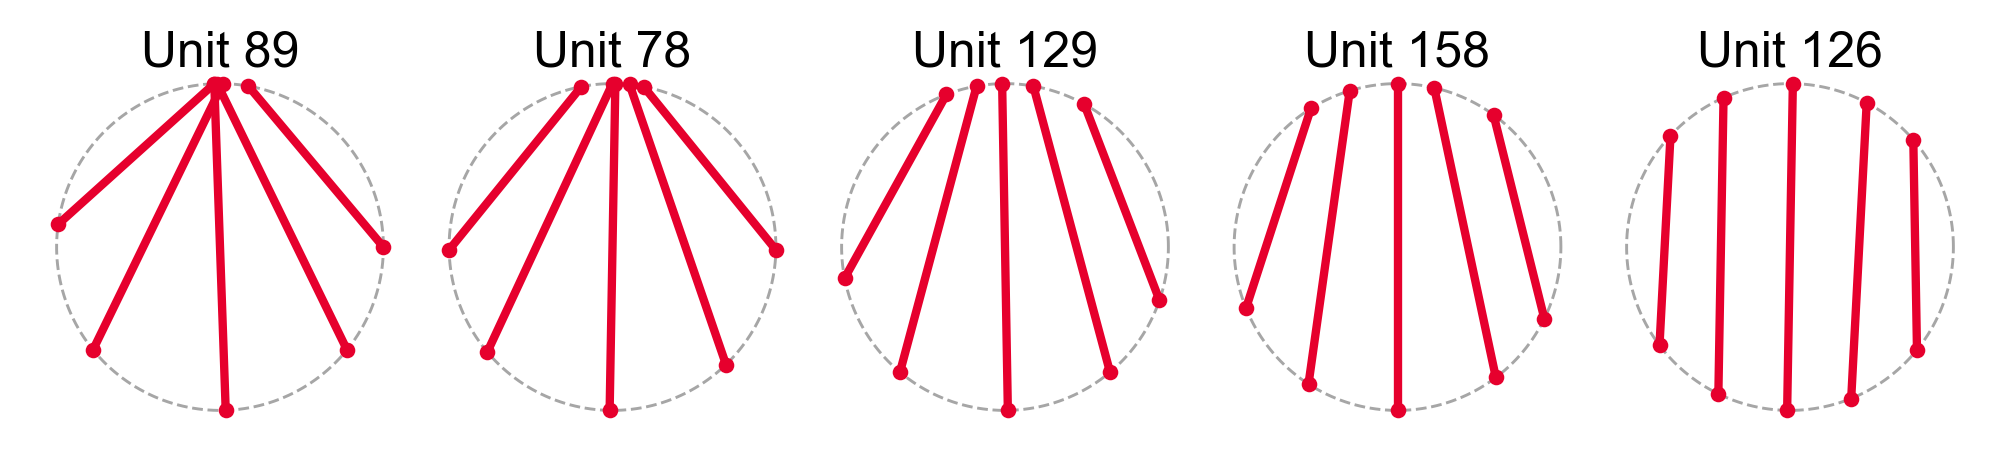

In [14]:
fig, axes = plt.subplots(1, len(units), figsize=(len(units) * PANEL_IN + 0.3, PANEL_IN + 0.5),
                         squeeze=False)
for col, ((s, ses, u, deg), ch) in enumerate(zip(units, chords)):
    ax = axes[0, col]
    draw_ring(ax, ch, np.radians(deg) if ROTATE else 0.0)
    ax.set_title(f'Unit {u}', fontsize=12, pad=TITLE_PAD, y=1.0)
fig.tight_layout(w_pad=0.3)
common.save(fig, OUTPUT)
plt.show()


## The relationality metric

Idealized relational-bias neurons at `N_LEVELS` relationalities *r*: each ring shows the stimuli
the model fires most for. → `figure_example_neurons_metric.pdf`


saved figure_example_neurons_metric.pdf


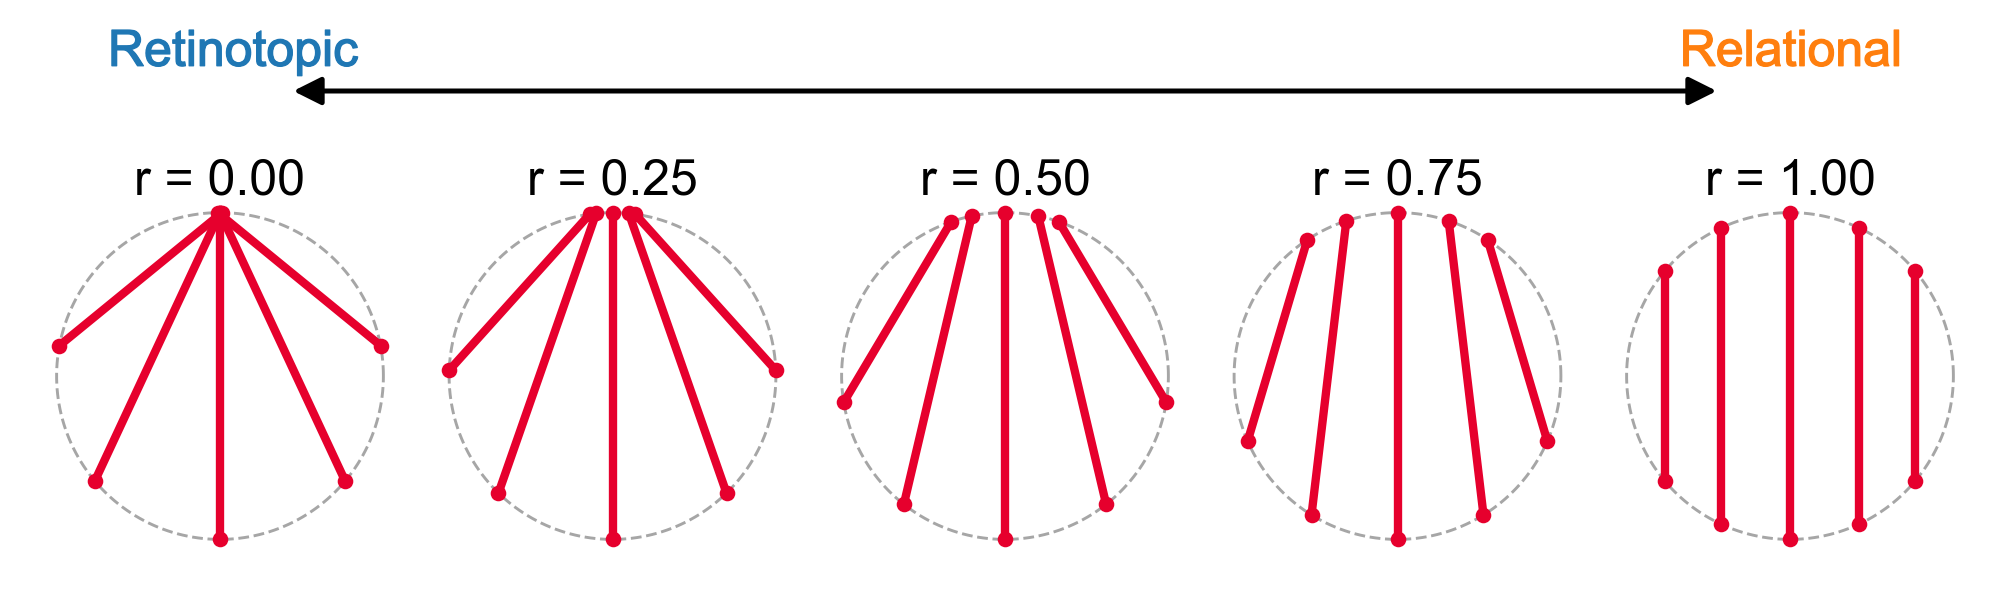

In [15]:
levels = np.linspace(0.0, 1.0, N_LEVELS)
metric_chords = []
for b in levels:
    p = enl.neuron_params(b, THETA_DEG, RF_HWHM_DEG, BASELINE, AMPLITUDE)
    # The neuron's response range over every drawn separation, which TIE_TOL is a fraction of.
    allr = [r for sep in SEPARATIONS for k in ('max', 'min')
            for *_, r in enl.extreme_pairs(p, sep, 1, k)]
    rng = max(allr) - min(allr)
    out = []
    for sep, n in SEPARATIONS.items():
        found = enl.extreme_pairs(p, sep, n, 'max')
        for i, (a, c, r) in enumerate(found):
            if i == 0 or abs(r - found[0][2]) <= TIE_TOL * rng or SHOW_ALL_EXTREMA:
                out.append((a, c, r, sep))
    metric_chords.append(out)

room = ARROW_ROOM_IN if METRIC_ARROW else 0.0
height = PANEL_IN + 0.6 + room
fig, axes = plt.subplots(1, N_LEVELS, figsize=(N_LEVELS * PANEL_IN + 0.3, height),
                         squeeze=False)
for col, (b, ch) in enumerate(zip(levels, metric_chords)):
    ax = axes[0, col]
    draw_ring(ax, ch)
    ax.set_title(f'r = {b:.2f}', fontsize=12, pad=TITLE_PAD, y=1.0)
fig.tight_layout(w_pad=0.3, rect=(0, 0, 1, 1 - room / height))
if METRIC_ARROW:
    direction_arrow(fig, axes[0])
common.save(fig, OUTPUT_METRIC)
plt.show()
